In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv


In [4]:

import pandas as pd

# Load dataset
df = pd.read_csv(
    '/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv'
)

# 1. Dataset Shape
print("Dataset Shape:", df.shape)

# 2. Column Names
print("\nColumns:")
print(df.columns.tolist())

# 3. Dataset Information
print("\nDataset Info:")
df.info()

# 4. Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# 5. Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())

# 6. First 5 Rows
print("\nFirst 5 Rows:")
display(df.head())

# 7. Target Distribution
if 'product' in df.columns:
    print("\nProduct Distribution:")
    display(df['product'].value_counts())

    print("\nNumber of Classes:", df['product'].nunique())

# 8. Complaint Samples
if 'narrative' in df.columns:
    print("\nAvailable Complaints:", df['narrative'].notna().sum())

    print("\nSample Complaints:")
    display(df['narrative'].dropna().head(5))


Dataset Shape: (162421, 3)

Columns:
['Unnamed: 0', 'product', 'narrative']

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 162421 entries, 0 to 162420
Data columns (total 3 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Unnamed: 0  162421 non-null  int64 
 1   product     162421 non-null  object
 2   narrative   162411 non-null  object
dtypes: int64(1), object(2)
memory usage: 3.7+ MB

Missing Values:
Unnamed: 0     0
product        0
narrative     10
dtype: int64

Duplicate Rows: 0

First 5 Rows:


,Unnamed: 0,product,narrative
0,0,credit_card,purchase order day shipping amount receive pro...
1,1,credit_card,forwarded message date tue subject please inve...
2,2,retail_banking,forwarded message cc sent friday pdt subject f...
3,3,credit_reporting,payment history missing credit report speciali...
4,4,credit_reporting,payment history missing credit report made mis...



Product Distribution:


product
credit_reporting       91179
debt_collection        23150
mortgages_and_loans    18990
credit_card            15566
retail_banking         13536
Name: count, dtype: int64


Number of Classes: 5

Available Complaints: 162411

Sample Complaints:


0    purchase order day shipping amount receive pro...
1    forwarded message date tue subject please inve...
2    forwarded message cc sent friday pdt subject f...
3    payment history missing credit report speciali...
4    payment history missing credit report made mis...
Name: narrative, dtype: object

Dataset Shape After Cleaning: (124676, 2)

Class Distribution:


,Count,Percentage
product,,
credit_reporting,56303,45.16
debt_collection,21117,16.94
mortgages_and_loans,18759,15.05
credit_card,15024,12.05
retail_banking,13473,10.81


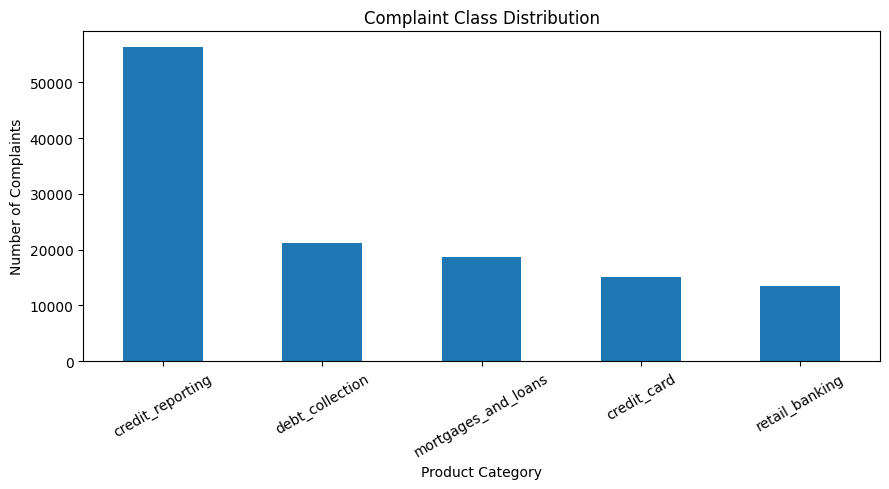


Complaint Length Statistics:


count    124676.000000
mean         87.117055
std         110.875369
min           1.000000
25%          30.000000
50%          58.000000
75%         104.000000
max        2685.000000
Name: text_length, dtype: float64

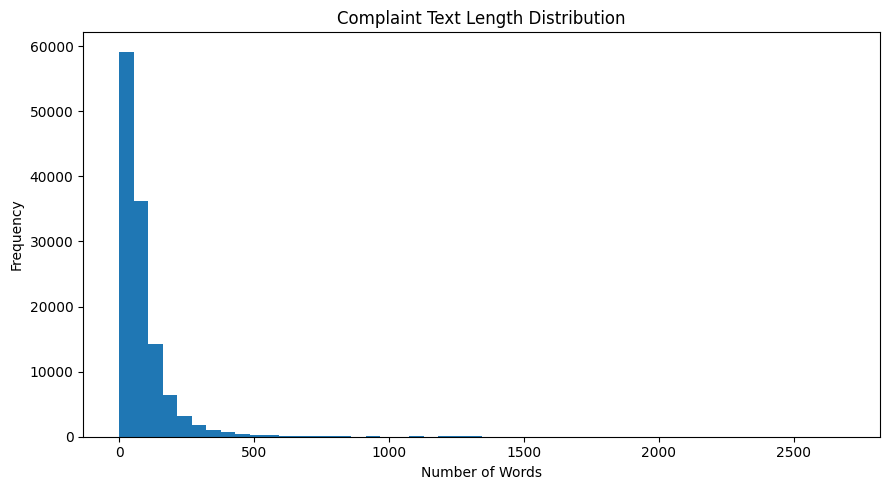


Top 20 Most Frequent Words:


,Word,Frequency
0,account,252929
1,credit,239624
2,report,124293
3,payment,118364
4,information,104300
5,time,73355
6,would,72341
7,loan,70670
8,company,67883
9,card,66770


In [5]:

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
import re

# 1. Remove unnecessary column
df = df.drop(columns=['Unnamed: 0'])

# 2. Remove missing values
df = df.dropna(subset=['narrative', 'product'])

# 3. Remove empty narratives
df = df[df['narrative'].str.strip() != '']

# 4. Check duplicates
df = df.drop_duplicates(subset=['narrative', 'product'])

# 5. Class distribution
print("Dataset Shape After Cleaning:", df.shape)

print("\nClass Distribution:")
class_counts = df['product'].value_counts()
class_percentages = df['product'].value_counts(normalize=True) * 100

display(pd.DataFrame({
    'Count': class_counts,
    'Percentage': class_percentages.round(2)
}))

# Class distribution chart
class_counts.plot(kind='bar', figsize=(9, 5))
plt.title('Complaint Class Distribution')
plt.xlabel('Product Category')
plt.ylabel('Number of Complaints')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 6. Complaint length analysis
df['text_length'] = df['narrative'].apply(lambda x: len(x.split()))

print("\nComplaint Length Statistics:")
display(df['text_length'].describe())

plt.figure(figsize=(9, 5))
plt.hist(df['text_length'], bins=50)
plt.title('Complaint Text Length Distribution')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# 7. Most frequent words
all_words = ' '.join(df['narrative'].astype(str)).lower()
words = re.findall(r'\b[a-z]+\b', all_words)

word_counts = Counter(words).most_common(20)

print("\nTop 20 Most Frequent Words:")
display(pd.DataFrame(word_counts, columns=['Word', 'Frequency']))


In [6]:
# 1. Class distribution
print("CLASS DISTRIBUTION")
print(df['product'].value_counts())

print("\nCLASS PERCENTAGES")
print((df['product'].value_counts(normalize=True) * 100).round(2))

# 2. Complaint length statistics
print("\nTEXT LENGTH STATISTICS")
print(df['text_length'].describe().round(2))

# 3. Text length percentiles
print("\nTEXT LENGTH PERCENTILES")
print(df['text_length'].quantile(
    [0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
))

# 4. Most frequent words
print("\nTOP 20 WORDS")
print(pd.DataFrame(
    Counter(" ".join(df['narrative'].astype(str)).split())
    .most_common(20),
    columns=['Word', 'Frequency']
).to_string(index=False))

# 5. Empty and missing text
print("\nDATA QUALITY")
print("Missing values:", df['narrative'].isna().sum())
print("Empty texts:", (df['narrative'].str.strip() == '').sum())

CLASS DISTRIBUTION
product
credit_reporting       56303
debt_collection        21117
mortgages_and_loans    18759
credit_card            15024
retail_banking         13473
Name: count, dtype: int64

CLASS PERCENTAGES
product
credit_reporting       45.16
debt_collection        16.94
mortgages_and_loans    15.05
credit_card            12.05
retail_banking         10.81
Name: proportion, dtype: float64

TEXT LENGTH STATISTICS
count    124676.00
mean         87.12
std         110.88
min           1.00
25%          30.00
50%          58.00
75%         104.00
max        2685.00
Name: text_length, dtype: float64

TEXT LENGTH PERCENTILES
0.25     30.0
0.50     58.0
0.75    104.0
0.90    180.0
0.95    252.0
0.99    501.0
Name: text_length, dtype: float64

TOP 20 WORDS
       Word  Frequency
    account     252929
     credit     239624
     report     124293
    payment     118364
information     104300
       time      73355
      would      72341
       loan      70670
    company      67883


In [7]:
df = df.drop_duplicates(subset=['narrative', 'product'])

In [8]:
import pandas as pd

path = '/kaggle/input/datasets/shashwatwork/consume-complaints-dataset-fo-nlp/complaints_processed.csv'

raw_df = pd.read_csv(path)

print("Original rows:", len(raw_df))

print("Exact full-row duplicates:",
      raw_df.duplicated().sum())

print("Duplicate narrative + product:",
      raw_df.duplicated(subset=['narrative', 'product']).sum())

print("Duplicate narratives regardless of product:",
      raw_df.duplicated(subset=['narrative']).sum())

print("Missing narratives:",
      raw_df['narrative'].isna().sum())

Original rows: 162421
Exact full-row duplicates: 0
Duplicate narrative + product: 37742
Duplicate narratives regardless of product: 37948
Missing narratives: 10


In [9]:
# 1. Number of repeated complaints
print("Repeated narrative + same product:",
      raw_df.duplicated(['narrative', 'product']).sum())

# 2. Number of narratives with different product labels
label_counts = raw_df.groupby('narrative')['product'].nunique()

conflicting_texts = label_counts[label_counts > 1]

print("\nNarratives with different labels:",
      len(conflicting_texts))

# 3. Display examples of conflicting labels
conflict_examples = raw_df[
    raw_df['narrative'].isin(conflicting_texts.index)
][['product', 'narrative']]

display(conflict_examples.head(10))

# 4. Compare class distribution before and after removing duplicates
print("\nBEFORE REMOVING DUPLICATES:")
print(raw_df['product'].value_counts())

print("\nAFTER REMOVING DUPLICATES:")
print(df['product'].value_counts())

# 5. Show examples of repeated complaints with the same label
same_label_duplicates = raw_df[
    raw_df.duplicated(
        subset=['narrative', 'product'],
        keep=False
    )
]

print("\nSAME-LABEL DUPLICATE EXAMPLES:")
display(
    same_label_duplicates[
        ['product', 'narrative']
    ].drop_duplicates().head(10)
)

Repeated narrative + same product: 37742

Narratives with different labels: 172


,product,narrative
521,credit_reporting,filed dispute regard incorrect item credit rep...
643,credit_reporting,writing due failed remove information affiliat...
647,debt_collection,intend pursue litigation accordance fcra seek ...
648,mortgages_and_loans,intend pursue litigation accordance fcra seek ...
649,debt_collection,intend pursue litigation accordance fcra seek ...
650,debt_collection,intend pursue litigation accordance fcra seek ...
651,debt_collection,intend pursue litigation accordance fcra seek ...
652,mortgages_and_loans,intend pursue litigation accordance fcra seek ...
657,debt_collection,identity compromised somebody know please feel...
673,debt_collection,shocked reviewed credit report week found mult...



BEFORE REMOVING DUPLICATES:
product
credit_reporting       91179
debt_collection        23150
mortgages_and_loans    18990
credit_card            15566
retail_banking         13536
Name: count, dtype: int64

AFTER REMOVING DUPLICATES:
product
credit_reporting       56303
debt_collection        21117
mortgages_and_loans    18759
credit_card            15024
retail_banking         13473
Name: count, dtype: int64

SAME-LABEL DUPLICATE EXAMPLES:


,product,narrative
31,credit_reporting,name last four s account number writing disput...
42,credit_reporting,open account acct opened balance account acct ...
68,credit_reporting,hello name trying reach several time get probl...
111,credit_reporting,name trying make change credit report since sa...
119,credit_reporting,name trying fix incorrect information credit r...
168,credit_reporting,block except otherwise provided section consum...
169,credit_reporting,block except otherwise provided section consum...
171,credit_reporting,block except otherwise provided section consum...
315,credit_reporting,blockexcept otherwise provided section consume...
316,credit_reporting,blockexcept otherwise provided section consume...


In [10]:
# 1. Find complaints with conflicting labels
label_counts = raw_df.groupby('narrative')['product'].nunique()

conflicting_texts = label_counts[label_counts > 1].index

# 2. Start with the dataset after removing same-label duplicates
final_df = df.copy()

# 3. Remove complaints with conflicting labels
final_df = final_df[
    ~final_df['narrative'].isin(conflicting_texts)
].copy()

# 4. Check final dataset
print("Final Dataset Shape:", final_df.shape)

print("\nFinal Class Distribution:")
print(final_df['product'].value_counts())

print("\nRemaining Conflicting Labels:",
      final_df.groupby('narrative')['product'].nunique().gt(1).sum())

Final Dataset Shape: (124300, 3)

Final Class Distribution:
product
credit_reporting       56172
debt_collection        20998
mortgages_and_loans    18701
credit_card            14963
retail_banking         13466
Name: count, dtype: int64

Remaining Conflicting Labels: 0


In [11]:
from sklearn.model_selection import train_test_split

# Features and target
X = final_df['narrative']
y = final_df['product']

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTraining Distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation Distribution:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTesting Distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training: 87010
Validation: 18645
Testing: 18645

Training Distribution:
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.05
credit_card            12.04
retail_banking         10.83
Name: proportion, dtype: float64

Validation Distribution:
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.04
credit_card            12.04
retail_banking         10.83
Name: proportion, dtype: float64

Testing Distribution:
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.04
credit_card            12.04
retail_banking         10.83
Name: proportion, dtype: float64


In [12]:
from sklearn.model_selection import train_test_split

# Features and target
X = final_df['narrative']
y = final_df['product']

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

print("\nTraining Distribution:")
print((y_train.value_counts(normalize=True) * 100).round(2))

print("\nValidation Distribution:")
print((y_val.value_counts(normalize=True) * 100).round(2))

print("\nTesting Distribution:")
print((y_test.value_counts(normalize=True) * 100).round(2))

Training: 87010
Validation: 18645
Testing: 18645

Training Distribution:
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.05
credit_card            12.04
retail_banking         10.83
Name: proportion, dtype: float64

Validation Distribution:
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.04
credit_card            12.04
retail_banking         10.83
Name: proportion, dtype: float64

Testing Distribution:
product
credit_reporting       45.19
debt_collection        16.89
mortgages_and_loans    15.04
credit_card            12.04
retail_banking         10.83
Name: proportion, dtype: float64


In [13]:
from tensorflow.keras.preprocessing.text import Tokenizer

# Create tokenizer
tokenizer = Tokenizer(
    num_words=20000,
    oov_token="<OOV>"
)

# Learn vocabulary from training data only
tokenizer.fit_on_texts(X_train)

# Convert text into sequences
X_train_seq = tokenizer.texts_to_sequences(X_train)
X_val_seq = tokenizer.texts_to_sequences(X_val)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("Vocabulary Size:", len(tokenizer.word_index))
print("Training Samples:", len(X_train_seq))
print("Validation Samples:", len(X_val_seq))
print("Testing Samples:", len(X_test_seq))

I0000 00:00:1794134435.885687     873 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Vocabulary Size: 39332
Training Samples: 87010
Validation Samples: 18645
Testing Samples: 18645


In [14]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 256

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_val_pad = pad_sequences(
    X_val_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding='post',
    truncating='post'
)

print("Training Shape:", X_train_pad.shape)
print("Validation Shape:", X_val_pad.shape)
print("Testing Shape:", X_test_pad.shape)

Training Shape: (87010, 256)
Validation Shape: (18645, 256)
Testing Shape: (18645, 256)


In [15]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

print("Classes:", label_encoder.classes_)
print("Training Labels Shape:", y_train_enc.shape)
print("Validation Labels Shape:", y_val_enc.shape)
print("Testing Labels Shape:", y_test_enc.shape)

Classes: ['credit_card' 'credit_reporting' 'debt_collection' 'mortgages_and_loans'
 'retail_banking']
Training Labels Shape: (87010,)
Validation Labels Shape: (18645,)
Testing Labels Shape: (18645,)


In [16]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train_enc)

weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_enc
)

class_weights = dict(zip(classes, weights))

print("Class Weights:")
for class_id, weight in class_weights.items():
    print(f"{label_encoder.classes_[class_id]}: {weight:.4f}")

Class Weights:
credit_card: 1.6614
credit_reporting: 0.4426
debt_collection: 1.1839
mortgages_and_loans: 1.3293
retail_banking: 1.8462


In [17]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build SimpleRNN Model
simple_rnn_model = Sequential([
    Embedding(
        input_dim=20000,
        output_dim=64,
        mask_zero=True
    ),

    SimpleRNN(32),

    Dropout(0.3),

    Dense(5, activation='softmax')
])

# Compile Model
simple_rnn_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Display Model Architecture
simple_rnn_model.summary()

# Early Stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

# Train Model
history_rnn = simple_rnn_model.fit(
    X_train_pad,
    y_train_enc,
    validation_data=(X_val_pad, y_val_enc),
    epochs=10,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - accuracy: 0.5823 - loss: 1.0618 - val_accuracy: 0.7229 - val_loss: 0.7976
Epoch 2/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.7350 - loss: 0.7497 - val_accuracy: 0.6582 - val_loss: 0.9018
Epoch 3/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.6827 - loss: 0.8830 - val_accuracy: 0.7497 - val_loss: 0.7160
Epoch 4/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.6252 - loss: 0.9563 - val_accuracy: 0.4799 - val_loss: 1.3019
Epoch 5/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.6368 - loss: 0.9172 - val_accuracy: 0.6446 - val_loss: 0.9188


In [18]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

# Predict test data
y_pred_probs = simple_rnn_model.predict(X_test_pad)

y_pred = np.argmax(y_pred_probs, axis=1)

# Classification Report
print("SimpleRNN Classification Report:\n")

print(classification_report(
    y_test_enc,
    y_pred,
    target_names=label_encoder.classes_,
    digits=4
))

# Confusion Matrix
cm = confusion_matrix(y_test_enc, y_pred)

print("\nConfusion Matrix:")
print(cm)

583/583 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step
SimpleRNN Classification Report:

                     precision    recall  f1-score   support

        credit_card     0.6296    0.7305    0.6763      2245
   credit_reporting     0.9137    0.6964    0.7904      8426
    debt_collection     0.6032    0.7593    0.6723      3149
mortgages_and_loans     0.6959    0.8556    0.7675      2805
     retail_banking     0.7270    0.7936    0.7588      2020

           accuracy                         0.7456     18645
          macro avg     0.7139    0.7671    0.7331     18645
       weighted avg     0.7741    0.7456    0.7499     18645


Confusion Matrix:
[[1640   89   81   61  374]
 [ 543 5868 1306  632   77]
 [ 138  384 2391  207   29]
 [  41   70  172 2400  122]
 [ 243   11   14  149 1603]]


In [19]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

lstm_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=20000, output_dim=64, mask_zero=True),
    LSTM(32),
    Dropout(0.3),
    Dense(5, activation='softmax')
])

lstm_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

lstm_model.summary()

early_stop_lstm = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history_lstm = lstm_model.fit(
    X_train_pad,
    y_train_enc,
    validation_data=(X_val_pad, y_val_enc),
    epochs=10,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop_lstm],
    verbose=1
)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 256, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,581 (4.93 MB)

 Trainable params: 1,292,581 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.6861 - loss: 0.8432 - val_accuracy: 0.8150 - val_loss: 0.5694
Epoch 2/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.7917 - loss: 0.6002 - val_accuracy: 0.7973 - val_loss: 0.5921
Epoch 3/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8216 - loss: 0.5376 - val_accuracy: 0.8079 - val_loss: 0.5677
Epoch 4/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8376 - loss: 0.4821 - val_accuracy: 0.8187 - val_loss: 0.5388
Epoch 5/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8457 - loss: 0.4497 - val_accuracy: 0.8253 - val_loss: 0.5352
Epoch 6/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8597 - loss: 0.4078 - val_accuracy: 0.8220 - val_loss: 0.5403
Epoch 7/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8645 - loss: 0.3905 - val_accuracy: 0.8311 - val_loss: 0.5164
Epoch 8/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8521 - loss: 0.4584 - v

In [20]:
y_pred_probs_lstm = lstm_model.predict(X_test_pad)

y_pred_lstm = np.argmax(y_pred_probs_lstm, axis=1)

print("LSTM Classification Report:")

print(classification_report(
    y_test_enc,
    y_pred_lstm,
    target_names=label_encoder.classes_,
    digits=4
))

print("Confusion Matrix:")
print(confusion_matrix(y_test_enc, y_pred_lstm))

583/583 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
LSTM Classification Report:
                     precision    recall  f1-score   support

        credit_card     0.7058    0.8174    0.7575      2245
   credit_reporting     0.9225    0.8095    0.8623      8426
    debt_collection     0.7464    0.8047    0.7744      3149
mortgages_and_loans     0.7708    0.8766    0.8204      2805
     retail_banking     0.8262    0.8450    0.8355      2020

           accuracy                         0.8236     18645
          macro avg     0.7943    0.8307    0.8100     18645
       weighted avg     0.8334    0.8236    0.8256     18645

Confusion Matrix:
[[1835  118   55   44  193]
 [ 369 6821  681  493   62]
 [ 134  302 2534  136   43]
 [  64  133   88 2459   61]
 [ 198   20   37   58 1707]]


In [21]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

gru_model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(input_dim=20000, output_dim=64, mask_zero=True),
    GRU(32),
    Dropout(0.3),
    Dense(5, activation='softmax')
])

gru_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

gru_model.summary()

early_stop_gru = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history_gru = gru_model.fit(
    X_train_pad,
    y_train_enc,
    validation_data=(X_val_pad, y_val_enc),
    epochs=10,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[early_stop_gru],
    verbose=1
)

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 256, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,289,573 (4.92 MB)

 Trainable params: 1,289,573 (4.92 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 11s 14ms/step - accuracy: 0.6834 - loss: 0.8056 - val_accuracy: 0.8183 - val_loss: 0.5338
Epoch 2/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8310 - loss: 0.4855 - val_accuracy: 0.8317 - val_loss: 0.5008
Epoch 3/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8508 - loss: 0.4193 - val_accuracy: 0.8326 - val_loss: 0.4857
Epoch 4/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8636 - loss: 0.3783 - val_accuracy: 0.8298 - val_loss: 0.4971
Epoch 5/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8722 - loss: 0.3475 - val_accuracy: 0.8398 - val_loss: 0.4804
Epoch 6/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8816 - loss: 0.3182 - val_accuracy: 0.8291 - val_loss: 0.5257
Epoch 7/10
680/680 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.8911 - loss: 0.2925 - val_accuracy: 0.8163 - val_loss: 0.5764


In [22]:
y_pred_probs_gru = gru_model.predict(X_test_pad)

y_pred_gru = np.argmax(y_pred_probs_gru, axis=1)

print("GRU Classification Report:")

print(classification_report(
    y_test_enc,
    y_pred_gru,
    target_names=label_encoder.classes_,
    digits=4
))

print("Confusion Matrix:")

print(confusion_matrix(y_test_enc, y_pred_gru))

583/583 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step
GRU Classification Report:
                     precision    recall  f1-score   support

        credit_card     0.7270    0.8339    0.7768      2245
   credit_reporting     0.9234    0.8242    0.8710      8426
    debt_collection     0.7537    0.8095    0.7806      3149
mortgages_and_loans     0.7849    0.8909    0.8345      2805
     retail_banking     0.8548    0.8391    0.8469      2020

           accuracy                         0.8345     18645
          macro avg     0.8087    0.8395    0.8220     18645
       weighted avg     0.8428    0.8345    0.8363     18645

Confusion Matrix:
[[1872  123   45   56  149]
 [ 343 6945  659  437   42]
 [ 116  316 2549  139   29]
 [  28  117   93 2499   68]
 [ 216   20   36   53 1695]]


In [23]:
import torch
import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU Available:", torch.cuda.is_available())

PyTorch: 2.11.0+cu130
Transformers: 5.20.2
GPU Available: True


In [24]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_NAME = "distilbert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

bert_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=5
)

print("Model Loaded Successfully!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model Loaded Successfully!


In [25]:
MAX_LENGTH = 256

train_encodings = bert_tokenizer(
    X_train.tolist(),
    truncation=True,
    padding=True,
    max_length=MAX_LENGTH
)

val_encodings = bert_tokenizer(
    X_val.tolist(),
    truncation=True,
    padding=True,
    max_length=MAX_LENGTH
)

test_encodings = bert_tokenizer(
    X_test.tolist(),
    truncation=True,
    padding=True,
    max_length=MAX_LENGTH
)

print("Training samples:", len(train_encodings["input_ids"]))
print("Validation samples:", len(val_encodings["input_ids"]))
print("Testing samples:", len(test_encodings["input_ids"]))

Training samples: 87010
Validation samples: 18645
Testing samples: 18645


In [26]:
from torch.utils.data import Dataset

class ComplaintDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            int(self.labels.iloc[idx]),
            dtype=torch.long
        )

        return item


train_dataset = ComplaintDataset(train_encodings, y_train_enc)
val_dataset = ComplaintDataset(val_encodings, y_val_enc)
test_dataset = ComplaintDataset(test_encodings, y_test_enc)

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

Train: 87010
Validation: 18645
Test: 18645


In [27]:
from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 5439
Validation batches: 1166
Testing batches: 1166


In [28]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

bert_model.to(device)

class_weight_tensor = torch.tensor(
    [class_weights[i] for i in range(5)],
    dtype=torch.float
).to(device)

print("Device:", device)
print("Class Weights:", class_weight_tensor)

Device: cuda
Class Weights: tensor([1.6614, 0.4426, 1.1839, 1.3293, 1.8462], device='cuda:0')


In [29]:
import torch.nn as nn

from torch.optim import AdamW

criterion = nn.CrossEntropyLoss(
    weight=class_weight_tensor
)

optimizer = AdamW(
    bert_model.parameters(),
    lr=2e-5
)

print("Loss Function: CrossEntropyLoss")
print("Optimizer: AdamW")
print("Learning Rate: 2e-5")

Loss Function: CrossEntropyLoss
Optimizer: AdamW
Learning Rate: 2e-5


In [30]:
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm
import copy

def evaluate_model(model, data_loader):
    model.eval()

    all_preds = []
    all_labels = []
    total_loss = 0

    with torch.no_grad():
        for batch in tqdm(data_loader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            loss = criterion(outputs.logits, labels)
            total_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    avg_loss = total_loss / len(data_loader)
    accuracy = accuracy_score(all_labels, all_preds)
    macro_f1 = f1_score(all_labels, all_preds, average='macro')

    return avg_loss, accuracy, macro_f1

In [31]:
class ComplaintDataset(Dataset):

    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):

        item = {
            key: torch.tensor(val[idx])
            for key, val in self.encodings.items()
        }

        item["labels"] = torch.tensor(
            int(self.labels[idx]),
            dtype=torch.long
        )

        return item

In [32]:
train_dataset = ComplaintDataset(train_encodings, y_train_enc)
val_dataset = ComplaintDataset(val_encodings, y_val_enc)
test_dataset = ComplaintDataset(test_encodings, y_test_enc)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16)
test_loader = DataLoader(test_dataset, batch_size=16)

In [33]:
EPOCHS = 3

best_macro_f1 = 0
best_model_state = None

for epoch in range(EPOCHS):

    bert_model.train()
    total_loss = 0
    all_preds = []
    all_labels = []

    progress_bar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}")

    for batch in progress_bar:

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        loss = criterion(outputs.logits, labels)
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            bert_model.parameters(), 1.0
        )

        optimizer.step()

        total_loss += loss.item()

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.detach().cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    train_loss = total_loss / len(train_loader)
    train_accuracy = accuracy_score(all_labels, all_preds)

    val_loss, val_accuracy, val_macro_f1 = evaluate_model(
        bert_model, val_loader
    )

    print(f"\nEpoch {epoch+1}/{EPOCHS}")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_macro_f1:.4f}")

    if val_macro_f1 > best_macro_f1:
        best_macro_f1 = val_macro_f1
        best_model_state = copy.deepcopy(bert_model.state_dict())

print("\nBest Validation Macro F1:", best_macro_f1)

Epoch 1/3:   0%|          | 0/5439 [00:00<?, ?it/s]

  0%|          | 0/1166 [00:00<?, ?it/s]


Epoch 1/3
Training Loss: 0.5187
Training Accuracy: 0.8129
Validation Loss: 0.4166
Validation Accuracy: 0.8403
Validation Macro F1: 0.8342


Epoch 2/3:   0%|          | 0/5439 [00:00<?, ?it/s]

  0%|          | 0/1166 [00:00<?, ?it/s]


Epoch 2/3
Training Loss: 0.3805
Training Accuracy: 0.8616
Validation Loss: 0.4275
Validation Accuracy: 0.8562
Validation Macro F1: 0.8428


Epoch 3/3:   0%|          | 0/5439 [00:00<?, ?it/s]

  0%|          | 0/1166 [00:00<?, ?it/s]


Epoch 3/3
Training Loss: 0.3105
Training Accuracy: 0.8909
Validation Loss: 0.5073
Validation Accuracy: 0.8647
Validation Macro F1: 0.8478

Best Validation Macro F1: 0.8477608947741004


In [34]:
bert_model.load_state_dict(best_model_state)

test_loss, test_accuracy, test_macro_f1 = evaluate_model(
    bert_model, test_loader
)

print("DistilBERT Test Results")
print("-----------------------")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Macro F1: {test_macro_f1:.4f}")

  0%|          | 0/1166 [00:00<?, ?it/s]

DistilBERT Test Results
-----------------------
Test Loss: 0.4921
Test Accuracy: 0.8643
Test Macro F1: 0.8504


In [35]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

bert_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for batch in tqdm(test_loader):

        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        outputs = bert_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        preds = torch.argmax(outputs.logits, dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print(classification_report(
    all_labels,
    all_preds,
    target_names=label_encoder.classes_
))

cm = confusion_matrix(all_labels, all_preds)

print("Confusion Matrix:")
print(cm)

  0%|          | 0/1166 [00:00<?, ?it/s]

                     precision    recall  f1-score   support

        credit_card       0.83      0.79      0.81      2245
   credit_reporting       0.87      0.92      0.90      8426
    debt_collection       0.85      0.75      0.80      3149
mortgages_and_loans       0.88      0.85      0.86      2805
     retail_banking       0.88      0.90      0.89      2020

           accuracy                           0.86     18645
          macro avg       0.86      0.84      0.85     18645
       weighted avg       0.86      0.86      0.86     18645

Confusion Matrix:
[[1783  267   13   25  157]
 [ 120 7785  342  154   25]
 [ 115  528 2365  119   22]
 [  25  301   61 2372   46]
 [ 105   58   11   37 1809]]


In [36]:
import os
import joblib

save_dir = "/kaggle/working/distilbert_complaints_model"

os.makedirs(save_dir, exist_ok=True)

bert_model.save_pretrained(save_dir)
bert_tokenizer.save_pretrained(save_dir)

joblib.dump(
    label_encoder,
    os.path.join(save_dir, "label_encoder.pkl")
)

print("Model saved successfully!")
print("Save directory:", save_dir)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved successfully!
Save directory: /kaggle/working/distilbert_complaints_model


In [37]:
!pip install gradio -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.


In [38]:
import gradio as gr

print("Gradio Version:", gr.__version__)

Gradio Version: 6.30.0


In [39]:
import torch
import gradio as gr
import joblib

from transformers import AutoTokenizer, AutoModelForSequenceClassification

save_dir = "/kaggle/working/distilbert_complaints_model"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

loaded_tokenizer = AutoTokenizer.from_pretrained(save_dir)

loaded_model = AutoModelForSequenceClassification.from_pretrained(save_dir)

loaded_model.to(device)
loaded_model.eval()

loaded_label_encoder = joblib.load(
    f"{save_dir}/label_encoder.pkl"
)

print("Model loaded successfully!")
print("Device:", device)
print("Classes:", loaded_label_encoder.classes_)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Model loaded successfully!
Device: cuda
Classes: ['credit_card' 'credit_reporting' 'debt_collection' 'mortgages_and_loans'
 'retail_banking']


In [40]:
import torch.nn.functional as F

def predict_complaint(text):

    inputs = loaded_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=256
    ).to(device)

    with torch.no_grad():

        outputs = loaded_model(**inputs)

        probabilities = F.softmax(outputs.logits, dim=1)[0]

    results = {
        loaded_label_encoder.classes_[i]: float(probabilities[i])
        for i in range(5)
    }

    return results

In [41]:
test_text = "My credit card was charged twice for the same transaction."

prediction = predict_complaint(test_text)

print("Prediction Results:")
for category, probability in prediction.items():
    print(f"{category}: {probability:.2%}")

Prediction Results:
credit_card: 96.94%
credit_reporting: 1.17%
debt_collection: 0.79%
mortgages_and_loans: 0.13%
retail_banking: 0.97%


In [42]:
demo = gr.Interface(
    fn=predict_complaint,
    inputs=gr.Textbox(
        lines=6,
        placeholder="Enter your complaint here...",
        label="Complaint Text"
    ),
    outputs=gr.Label(
        num_top_classes=5,
        label="Prediction Results"
    ),
    title="Consumer Complaint Classification",
    description="AI-powered complaint classification using DistilBERT."
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://f243c7d07d5d072057.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [43]:
custom_css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#hero {
    text-align: center;
    padding: 35px;
    border-radius: 20px;
    background: linear-gradient(120deg, #111827, #312e81);
    color: white;
    margin-bottom: 20px;
}

#hero h1 {
    font-size: 32px;
    font-weight: 800;
}

#input-card, #result-card {
    border-radius: 18px;
    padding: 20px;
    border: 1px solid #6366f1;
}

button.primary {
    background: linear-gradient(90deg, #4f46e5, #7c3aed) !important;
    border: none !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(),
    css=custom_css
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>Consumer Complaint Intelligence</h1>
        <p>AI-Powered Text Classification using DistilBERT</p>
        <p>Intelligent complaint analysis across five financial categories</p>
    </div>
    """)

    with gr.Row():

        with gr.Column():
            with gr.Group(elem_id="input-card"):
                gr.Markdown("### Enter Your Complaint")

                complaint_input = gr.Textbox(
                    lines=8,
                    placeholder="Describe your financial complaint here...",
                    label="Complaint Description"
                )

                classify_btn = gr.Button(
                    "Analyze Complaint",
                    variant="primary",
                    size="lg"
                )

        with gr.Column():
            with gr.Group(elem_id="result-card"):
                gr.Markdown("### Classification Results")

                prediction_output = gr.Label(
                    num_top_classes=5,
                    label="Category Confidence"
                )

    classify_btn.click(
        fn=predict_complaint,
        inputs=complaint_input,
        outputs=prediction_output
    )

    gr.Markdown(
        "Powered by DistilBERT | Built with PyTorch & Gradio"
    )

demo.launch(share=True)

/tmp/ipykernel_873/595610559.py:33: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://8e3ae5e8eec909d6cd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [44]:
custom_css = """
.gradio-container {
    max-width: 1200px !important;
    margin: auto !important;
    background: #f7f8fc !important;
}

#hero {
    background: linear-gradient(120deg, #ffffff, #f0edff);
    padding: 38px;
    border-radius: 24px;
    border: 1px solid #e4defc;
    text-align: center;
    margin-bottom: 22px;
}

#hero h1 {
    color: #252052 !important;
    font-size: 38px !important;
    font-weight: 800 !important;
    margin-bottom: 12px;
}

#hero p {
    color: #555477 !important;
    font-size: 16px !important;
}

#stats {
    background: white;
    border: 1px solid #e8e8f2;
    border-radius: 18px;
    padding: 18px;
    text-align: center;
}

#input-card, #result-card {
    background: white;
    border: 1px solid #e6e5f0;
    border-radius: 20px;
    padding: 22px;
}

#input-card textarea {
    background: #fafaff !important;
    color: #24233b !important;
    border: 1px solid #dedcf0 !important;
}

button.primary {
    background: linear-gradient(90deg, #6246ea, #9161ed) !important;
    color: white !important;
    border: none !important;
    border-radius: 12px !important;
    font-weight: 700 !important;
}

button.primary:hover {
    filter: brightness(1.08);
}

footer {
    display: none !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="violet",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=custom_css
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>Consumer Complaint Intelligence</h1>
        <p>Transforming Financial Complaints into Intelligent Insights</p>
        <p>Powered by DistilBERT | Natural Language Processing</p>
    </div>
    """)

    with gr.Row():

        with gr.Column(elem_id="stats"):
            gr.Markdown("### 86.43%")
            gr.Markdown("Test Accuracy")

        with gr.Column(elem_id="stats"):
            gr.Markdown("### 85.04%")
            gr.Markdown("Test Macro F1")

        with gr.Column(elem_id="stats"):
            gr.Markdown("### 5")
            gr.Markdown("Complaint Categories")

    gr.Markdown("## Analyze a Complaint")

    with gr.Row():

        with gr.Column(scale=1):
            with gr.Group(elem_id="input-card"):

                gr.Markdown("### Complaint Details")

                complaint_input = gr.Textbox(
                    lines=9,
                    placeholder="Enter the financial complaint you want to classify...",
                    label="Complaint Text"
                )

                classify_btn = gr.Button(
                    "✦ Analyze Complaint",
                    variant="primary",
                    size="lg"
                )

        with gr.Column(scale=1):
            with gr.Group(elem_id="result-card"):

                gr.Markdown("### AI Prediction")

                prediction_output = gr.Label(
                    num_top_classes=5,
                    label="Predicted Categories"
                )

    classify_btn.click(
        fn=predict_complaint,
        inputs=complaint_input,
        outputs=prediction_output
    )

    gr.Markdown("""
    ---
    <center>
    <small>Developed with Python • PyTorch • Hugging Face • Gradio</small>
    </center>
    """)

demo.launch(share=True)

/tmp/ipykernel_873/1170268966.py:67: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7862
* Running on public URL: https://5cb53b279ea059c2cd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [45]:

custom_css = """
.gradio-container {
    max-width: 1200px !important;
    margin: auto !important;
    background: #f7f8fc !important;
}

#hero {
    background: linear-gradient(120deg, #ffffff, #f0edff);
    padding: 38px;
    border-radius: 24px;
    border: 1px solid #e4defc;
    text-align: center;
    margin-bottom: 22px;
}

#hero h1 {
    color: #252052 !important;
    font-size: 38px !important;
    font-weight: 800 !important;
    margin-bottom: 12px;
}

#hero p {
    color: #555477 !important;
    font-size: 16px !important;
}

#stats {
    background: white;
    border: 1px solid #e8e8f2;
    border-radius: 18px;
    padding: 18px;
    text-align: center;
}

#input-card, #result-card {
    background: white;
    border: 1px solid #e6e5f0;
    border-radius: 20px;
    padding: 22px;
}

#input-card textarea {
    background: #fafaff !important;
    color: #24233b !important;
    border: 1px solid #dedcf0 !important;
}

button.primary {
    background: linear-gradient(90deg, #6246ea, #9161ed) !important;
    color: white !important;
    border: none !important;
    border-radius: 12px !important;
    font-weight: 700 !important;
}

button.primary:hover {
    filter: brightness(1.08);
}

footer {
    display: none !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="violet",
        secondary_hue="blue",
        neutral_hue="slate"
    ),
    css=custom_css
) as demo:

    gr.HTML("""
    <div id="hero">
        <h1>Consumer Complaint Intelligence</h1>
        <p>Transforming Financial Complaints into Intelligent Insights</p>
        <p>Powered by DistilBERT | Natural Language Processing</p>
    </div>
    """)

    with gr.Row():

        with gr.Column(elem_id="stats"):
            gr.Markdown("### AI-Powered Analysis")
            gr.Markdown("Intelligent Text Analysis")

        with gr.Column(elem_id="stats"):
            gr.Markdown("### Real-Time Prediction")
            gr.Markdown("Instant Complaint Prediction")

        with gr.Column(elem_id="stats"):
            gr.Markdown("### 5 Financial Complaint Types")
            gr.Markdown("Financial Complaint Classification")

    gr.Markdown("## Analyze a Complaint")

    with gr.Row():

        with gr.Column(scale=1):
            with gr.Group(elem_id="input-card"):

                gr.Markdown("### Complaint Details")

                complaint_input = gr.Textbox(
                    lines=9,
                    placeholder="Enter the financial complaint you want to classify...",
                    label="Complaint Text"
                )

                with gr.Row():
                    classify_btn = gr.Button(
                        "✦ Analyze Complaint",
                        variant="primary",
                        size="lg"
                    )

                    clear_btn = gr.ClearButton(
                        components=[complaint_input],
                        value="Clear"
                    )

        with gr.Column(scale=1):
            with gr.Group(elem_id="result-card"):

                gr.Markdown("### AI Prediction")

                prediction_output = gr.Label(
                    num_top_classes=5,
                    label="Predicted Categories"
                )

    classify_btn.click(
        fn=predict_complaint,
        inputs=complaint_input,
        outputs=prediction_output
    )

    clear_btn.click(
        fn=lambda: None,
        inputs=None,
        outputs=prediction_output
    )

    gr.Markdown("""
    ---
    <center>
        <small>
        Developed with Python • PyTorch • Hugging Face • Gradio
        <br>
        AI-Powered Consumer Complaint Classification
        </small>
    </center>
    """)

demo.launch(share=True)


/tmp/ipykernel_873/4131854332.py:67: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


* Running on local URL:  http://127.0.0.1:7863
* Running on public URL: https://5b385d12317b911554.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
